In [1]:
import io
import zipfile
import requests
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

GENES = {
    "ROR1":  "ENSG00000185483",
    "EGFR":  "ENSG00000146648",
    "ERBB2": "ENSG00000141736",  # HER2
    "EPCAM": "ENSG00000119888",
}
GENE_SYMBOLS = set(GENES.keys())
ENSG_TO_SYMBOL = {v: k for k, v in GENES.items()}
HEADERS = {"User-Agent": "Mozilla/5.0 (research script; contact: you@example.com)"}

In [2]:
# -------------------------------------------------------------------------
# Michaelis-Menten coexpression score
# -------------------------------------------------------------------------

MM_K_QUANTILE = 0.75   # saturation point (75th percentile of expressing cells)
EPS = 1e-12

In [3]:
DVP_URL = "https://www.proteinatlas.org/download/tsv/dvp_cell_type_group_data.tsv.zip"

resp = requests.get(DVP_URL, headers=HEADERS, timeout=120)
resp.raise_for_status()

with zipfile.ZipFile(io.BytesIO(resp.content)) as zf:
    inner_name = zf.namelist()[0]
    with zf.open(inner_name) as f:
        dvp_df = pd.read_csv(f, sep="\t")

print(dvp_df.shape)
print(list(dvp_df.columns))
dvp_df.head()

(463128, 5)
['Gene', 'Gene name', 'Cell type name', 'Intensity', 'Matched nCPM']


,Gene,Gene name,Cell type name,Intensity,Matched nCPM
0,ENSG00000000003,TSPAN6,alveolar cell types,8827.5,11.6
1,ENSG00000000003,TSPAN6,astrocytes and neuropil,NaN,19.0
2,ENSG00000000003,TSPAN6,b-cells,NaN,0.1
3,ENSG00000000003,TSPAN6,capillaries,NaN,2.9
4,ENSG00000000003,TSPAN6,cardiomyocytes,NaN,0.8


In [4]:
dvp_df.columns = [c.strip() for c in dvp_df.columns]

col_map = {}
for c in dvp_df.columns:
    lc = c.lower()
    if lc in ("gene", "ensembl", "gene id", "ensembl gene id"):
        col_map[c] = "ensembl_id"
    elif "gene name" in lc:
        col_map[c] = "gene_name"
    elif "cell type group" in lc:
        col_map[c] = "cell_type_group"
    elif lc == "cell type":
        col_map[c] = "cell_type"
    elif "tissue" in lc:
        col_map[c] = "tissue"
    elif "abundance" in lc or "intensity" in lc or lc == "level":
        col_map[c] = "abundance"
    elif "reliability" in lc:
        col_map[c] = "reliability"

dvp_df = dvp_df.rename(columns=col_map)
print("Normalized columns:", list(dvp_df.columns))

Normalized columns: ['ensembl_id', 'gene_name', 'Cell type name', 'abundance', 'Matched nCPM']


In [5]:
if "ensembl_id" in dvp_df.columns:
    mask = dvp_df["ensembl_id"].isin(GENES.values())
elif "gene_name" in dvp_df.columns:
    mask = dvp_df["gene_name"].isin(GENE_SYMBOLS)
else:
    raise ValueError("Could not find a gene identifier column — inspect dvp_df.columns")

targets_dvp = dvp_df.loc[mask].copy()
targets_dvp["symbol"] = targets_dvp.get("ensembl_id", targets_dvp.get("gene_name")).map(
    lambda x: ENSG_TO_SYMBOL.get(x, x)
)

print(targets_dvp["symbol"].value_counts())
targets_dvp

symbol
EPCAM    24
ERBB2    24
EGFR     24
ROR1     24
Name: count, dtype: int64


,ensembl_id,gene_name,Cell type name,abundance,Matched nCPM,symbol
117504,ENSG00000119888,EPCAM,alveolar cell types,3010365.8,594.2,EPCAM
117505,ENSG00000119888,EPCAM,astrocytes and neuropil,NaN,1.7,EPCAM
117506,ENSG00000119888,EPCAM,b-cells,NaN,0.6,EPCAM
117507,ENSG00000119888,EPCAM,capillaries,NaN,0.0,EPCAM
117508,ENSG00000119888,EPCAM,cardiomyocytes,NaN,1.0,EPCAM
...,...,...,...,...,...,...
363523,ENSG00000185483,ROR1,pancreatic islets,49731.0,273.0,ROR1
363524,ENSG00000185483,ROR1,proximal tubules,1513.3,202.7,ROR1
363525,ENSG00000185483,ROR1,skeletal myofibers,NaN,94.5,ROR1
363526,ENSG00000185483,ROR1,smooth muscle cells,16973.3,202.9,ROR1


In [6]:
def michaelis_menten_score(ror1_expr, egfr_expr, k_r=None, k_e=None):
    """
    Calculate a bounded coexpression score between 0 and 1.

    Parameters
    ----------
    ror1_expr : ndarray
        Normalized ROR1 expression.
    egfr_expr : ndarray
        Normalized EGFR expression.
    k_r, k_e : float or None
        Michaelis constants. If None, estimated from the data.

    Returns
    -------
    score : ndarray
        Coexpression score.
    k_r, k_e : float
        Estimated Michaelis constants.
    """

    if k_r is None:
        pos = ror1_expr[ror1_expr > 0]
        k_r = np.quantile(pos, MM_K_QUANTILE) if len(pos) else 1.0

    if k_e is None:
        pos = egfr_expr[egfr_expr > 0]
        k_e = np.quantile(pos, MM_K_QUANTILE) if len(pos) else 1.0

    r_score = ror1_expr / (k_r + ror1_expr + EPS)
    e_score = egfr_expr / (k_e + egfr_expr + EPS)

    return r_score * e_score, k_r, k_e

Celltype Organ

In [7]:
CELLTYPE_TO_ORGAN = {
    # Blood and immune system
    "b-cells": "Blood / Immune",
    "t-cells": "Blood / Immune",
    "macrophages": "Blood / Immune",
    "neutrophils": "Blood / Immune",

    # Female reproductive system
    "fallopian tube cells": "Fallopian tube",
    "granulosa cells": "Ovary",
    "oocytes": "Ovary",

    # Pancreas
    "pancreatic islets": "Pancreas",
    "pancreas epithelial cells": "Pancreas",
    "large ducts": "Pancreas",

    # Kidney
    "glomeruli": "Kidney",
    "proximal tubules": "Kidney",
    "distal tubules": "Kidney",
    "collecting ducts": "Kidney",

    # Lung
    "alveolar cell types": "Lung",

    # Liver
    "hepatocytes": "Liver",

    # Heart
    "cardiomyocytes": "Heart",

    # Skeletal muscle
    "skeletal myofibers": "Skeletal muscle",

    # Brain / CNS
    "neurons": "Brain",
    "astrocytes and neuropil": "Brain",
    "microglia and neuropil": "Brain",

    # Skin
    "keratinocytes": "Skin",

    # Vasculature
    "capillaries": "Vasculature",
    "smooth muscle cells": "Vasculature",
}

In [8]:
ORGAN_ORDER = [
    "Blood / Immune",
    "Brain",
    "Heart",
    "Kidney",
    "Liver",
    "Lung",
    "Ovary",
    "Pancreas",
    "Skin",
    "Skeletal muscle",
    "Fallopian tube",
    "Vasculature",
]

Plot

In [9]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- Config: adjust these if your normalized column names differ ---
PIVOT_INDEX = "Cell type name"   # the 27 DVP cell type / shape labels
VALUE_COL   = "abundance"         # quantitative protein abundance
GENE_ORDER  = ["ROR1", "EGFR", "ERBB2", "EPCAM"]
GENE_COLORS = {
    "ROR1":  "#d62728",   # red
    "EGFR":  "#9467bd",   # purple
    "ERBB2": "#2ca02c",   # green
    "EPCAM": "#1f77b4",   # blue
}

In [10]:
SIZE_SCALE = 400
TARGET_PAIRS = {frozenset(["ROR1", "EGFR"]), frozenset(["ERBB2", "EPCAM"])}

In [11]:
# All HPA cell types
cell_types = sorted(targets_dvp[PIVOT_INDEX].unique())

# Pivot
abundance_wide = (
    targets_dvp
    .pivot_table(
        index=PIVOT_INDEX,
        columns="symbol",
        values=VALUE_COL,
        aggfunc="mean",
    )
    .reindex(index=cell_types, columns=GENE_ORDER)
    .fillna(0)
)

# Normalize each gene's abundance to 0-1 for dot sizing (per-gene, matching
# how HPA scales "total normalized abundance / reliability" in panel c)
abundance_norm = abundance_wide / abundance_wide.max()

n_cells = len(cell_types)
print(f"{n_cells} cell types found:", cell_types)

24 cell types found: ['alveolar cell types', 'astrocytes and neuropil', 'b-cells', 'capillaries', 'cardiomyocytes', 'collecting ducts', 'distal tubules', 'fallopian tube cells', 'glomeruli', 'granulosa cells', 'hepatocytes', 'keratinocytes', 'large ducts', 'macrophages', 'microglia and neuropil', 'neurons', 'neutrophils', 'oocytes', 'pancreas epithelial cells', 'pancreatic islets', 'proximal tubules', 'skeletal myofibers', 'smooth muscle cells', 't-cells']


In [12]:
# -------------------------------------------------------------------------
# Build plotting rows (organ headers + indented cell types)
# -------------------------------------------------------------------------
plot_rows = []

for organ in ORGAN_ORDER:

    members = [ct for ct in cell_types if CELLTYPE_TO_ORGAN[ct] == organ]

    if len(members) == 0:
        continue

    # Organ header
    plot_rows.append({
        "label": organ,
        "celltype": None,
        "is_header": True,
    })

    # Cell types
    for ct in members:
        plot_rows.append({
            "label": ct,
            "celltype": ct,
            "is_header": False,
        })

plot_labels = [r["label"] for r in plot_rows]
y_pos = np.arange(len(plot_rows))[::-1]

In [13]:
def plot_abundance_panel(
        ax,
        abundance_wide,
        abundance_norm,
        gene_order,
        gene_colors,
        plot_rows,
):

    size_scale = SIZE_SCALE

    for gi, gene in enumerate(gene_order):

        for yi, row in enumerate(plot_rows):

            if row["is_header"]:
                continue

            ct = row["celltype"]

            abundance = abundance_norm.loc[ct, gene]
            detected = abundance_wide.loc[ct, gene] > 0

            if detected:

                ax.scatter(
                    gi,
                    y_pos[yi],
                    s=abundance * size_scale,
                    color=gene_colors[gene],
                    alpha=0.85,
                    edgecolors="none",
                )

    ax.set_xticks(range(len(gene_order)))
    #ax.set_xticklabels(gene_order)
    gene_maxes = abundance_wide.max()  # one max value per gene (per column)
    xtick_labels = [
        f"{gene}\n({gene_maxes[gene]:,.0f})"
        for gene in GENE_ORDER
    ]
    axA.set_xticklabels(xtick_labels, fontsize=9)

    # Only show cell type names as y-axis labels
    celltype_labels = [
        row["label"] if not row["is_header"] else ""
        for row in plot_rows
    ]

    ax.set_yticks(y_pos)
    ax.set_yticklabels(celltype_labels)

    ax.set_xlim(-0.5, len(gene_order)-0.5)

    # Label explaining the xtick label format ("Gene" / "(Max Intensity)")
    ax.text(
        -0.02, -0.01,                 # just left of & below the axis origin
        "Gene\n(Max Intensity)",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        linespacing=1.3,
    )

    ax.spines[["top","right"]].set_visible(False)

    # Make organ labels bold
    for tick, row in zip(ax.get_yticklabels(), plot_rows):

        if not row["is_header"]:
            tick.set_fontsize(10)
            tick.set_horizontalalignment("right")

    # Add organ labels manually on the far left
    for yi, row in enumerate(plot_rows):

        if row["is_header"]:

            ax.text(-0.55,              # horizontal position (adjust if needed)
                y_pos[yi],
                row["label"],
                ha="left",
                va="center",
                fontsize=11,
                fontweight="bold",
                transform=ax.get_yaxis_transform(),
            )

gene_pairs = list(itertools.combinations(GENE_ORDER, 2))  # all 6 pairs

In [14]:
##FOR CUSTOM K PER GENE
#coexpression = pd.DataFrame(
#    index=cell_types,
#    columns=[f"{a}+{b}" for a, b in gene_pairs],
#    dtype=float,
#)

#K = {}

#for a, b in gene_pairs:

#    r = abundance_norm[a].reindex(cell_types).fillna(0).values
#    e = abundance_norm[b].reindex(cell_types).fillna(0).values

#    score, k_r, k_e = michaelis_menten_score(r, e)

#    coexpression[f"{a}+{b}"] = score

#    # Save the estimated K values (only once)
#    K.setdefault(a, k_r)
#    K.setdefault(b, k_e)

#print("Estimated Michaelis constants:")
#for gene, k in K.items():
#    print(f"{gene}: {k:.3f}")

In [15]:
#FOR SET K=0.2
# AND-gate: True where both genes in the pair are detected (abundance > 0)
# in that cell type
coexpression = pd.DataFrame(
    index=cell_types,
    columns=[f"{a}+{b}" for a, b in gene_pairs],
    dtype=float,
)

EPS = 1e-12
K_QUANTILE = 0.75

# Estimate one Michaelis constant per gene
K = {}

for gene in GENE_ORDER:
    positive = abundance_wide[gene]
    positive = positive[positive > 0]

    if len(positive):
        K[gene] = np.quantile(positive, K_QUANTILE)
    else:
        K[gene] = 1.0

print("Michaelis constants:")
for gene in GENE_ORDER:
    print(f"  {gene}: K = {K[gene]:.3f}")

# Compute pairwise AND-gate scores
for a, b in gene_pairs:

    r = abundance_wide[a].reindex(cell_types).fillna(0)
    e = abundance_wide[b].reindex(cell_types).fillna(0)

    r_mm = r / (K[a] + r + EPS)
    e_mm = e / (K[b] + e + EPS)

    coexpression[f"{a}+{b}"] = r_mm * e_mm

Michaelis constants:
  ROR1: K = 44359.150
  EGFR: K = 4459291.400
  ERBB2: K = 1714110.600
  EPCAM: K = 8681932.700


In [16]:
def plot_coexpression_panel(ax, coexpression, plot_rows):

    # same coordinate system as abundance panel
    y_pos = np.arange(len(plot_rows))[::-1]

    pair_cols = coexpression.columns.tolist()

    sc = None

    for pi, pair in enumerate(pair_cols):

        xs = []
        ys = []
        scores = []


        for yi, row in enumerate(plot_rows):

            if row["is_header"]:
                continue

            ct = row["celltype"]

            xs.append(pi)
            ys.append(y_pos[yi])
            scores.append(coexpression.loc[ct, pair])

        sc = ax.scatter(
            xs,
            ys,
            s=np.array(scores) * SIZE_SCALE,
            c=scores,
            cmap="viridis",
            vmin=0,
            vmax=1,
            edgecolors="none",
        )

    ax.set_xticks(range(len(pair_cols)))
    ax.set_xticklabels(pair_cols, rotation=45, ha="right")

    ax.set_yticks(y_pos)
    ax.set_yticklabels([])

    ax.spines[["top","right"]].set_visible(False)

    return sc

In [17]:
# CTLI = unweighted count of cell types where the pair's AND-gate is true
ctli = coexpression.sum(axis=0, skipna=True).sort_values()
#ctli = coexpression.mean(axis=0).sort_values()

def plot_ctli_panel(ax, ctli, target_pairs):
    colors = []
    for pair_label in ctli.index:
        a, b = pair_label.split("+")
        colors.append("#1f77b4" if frozenset([a, b]) in target_pairs else "lightgrey")

    ax.barh(ctli.index, ctli.values, color=colors)

    for i, (label, val) in enumerate(ctli.items()):
        ax.text(val * 1.2, i, f"{val:.2e}", va="center", fontsize=10)

    ax.set_xlabel(
        "Integrated co-expression score (log scale)\n(product of MM scores across cell types)",
        fontsize=10
    )
    ax.set_title("Integrated co-expression liability ranking", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12, "xtick.labelsize": 12, "ytick.labelsize": 12})
plt.rcParams["figure.dpi"] = 300

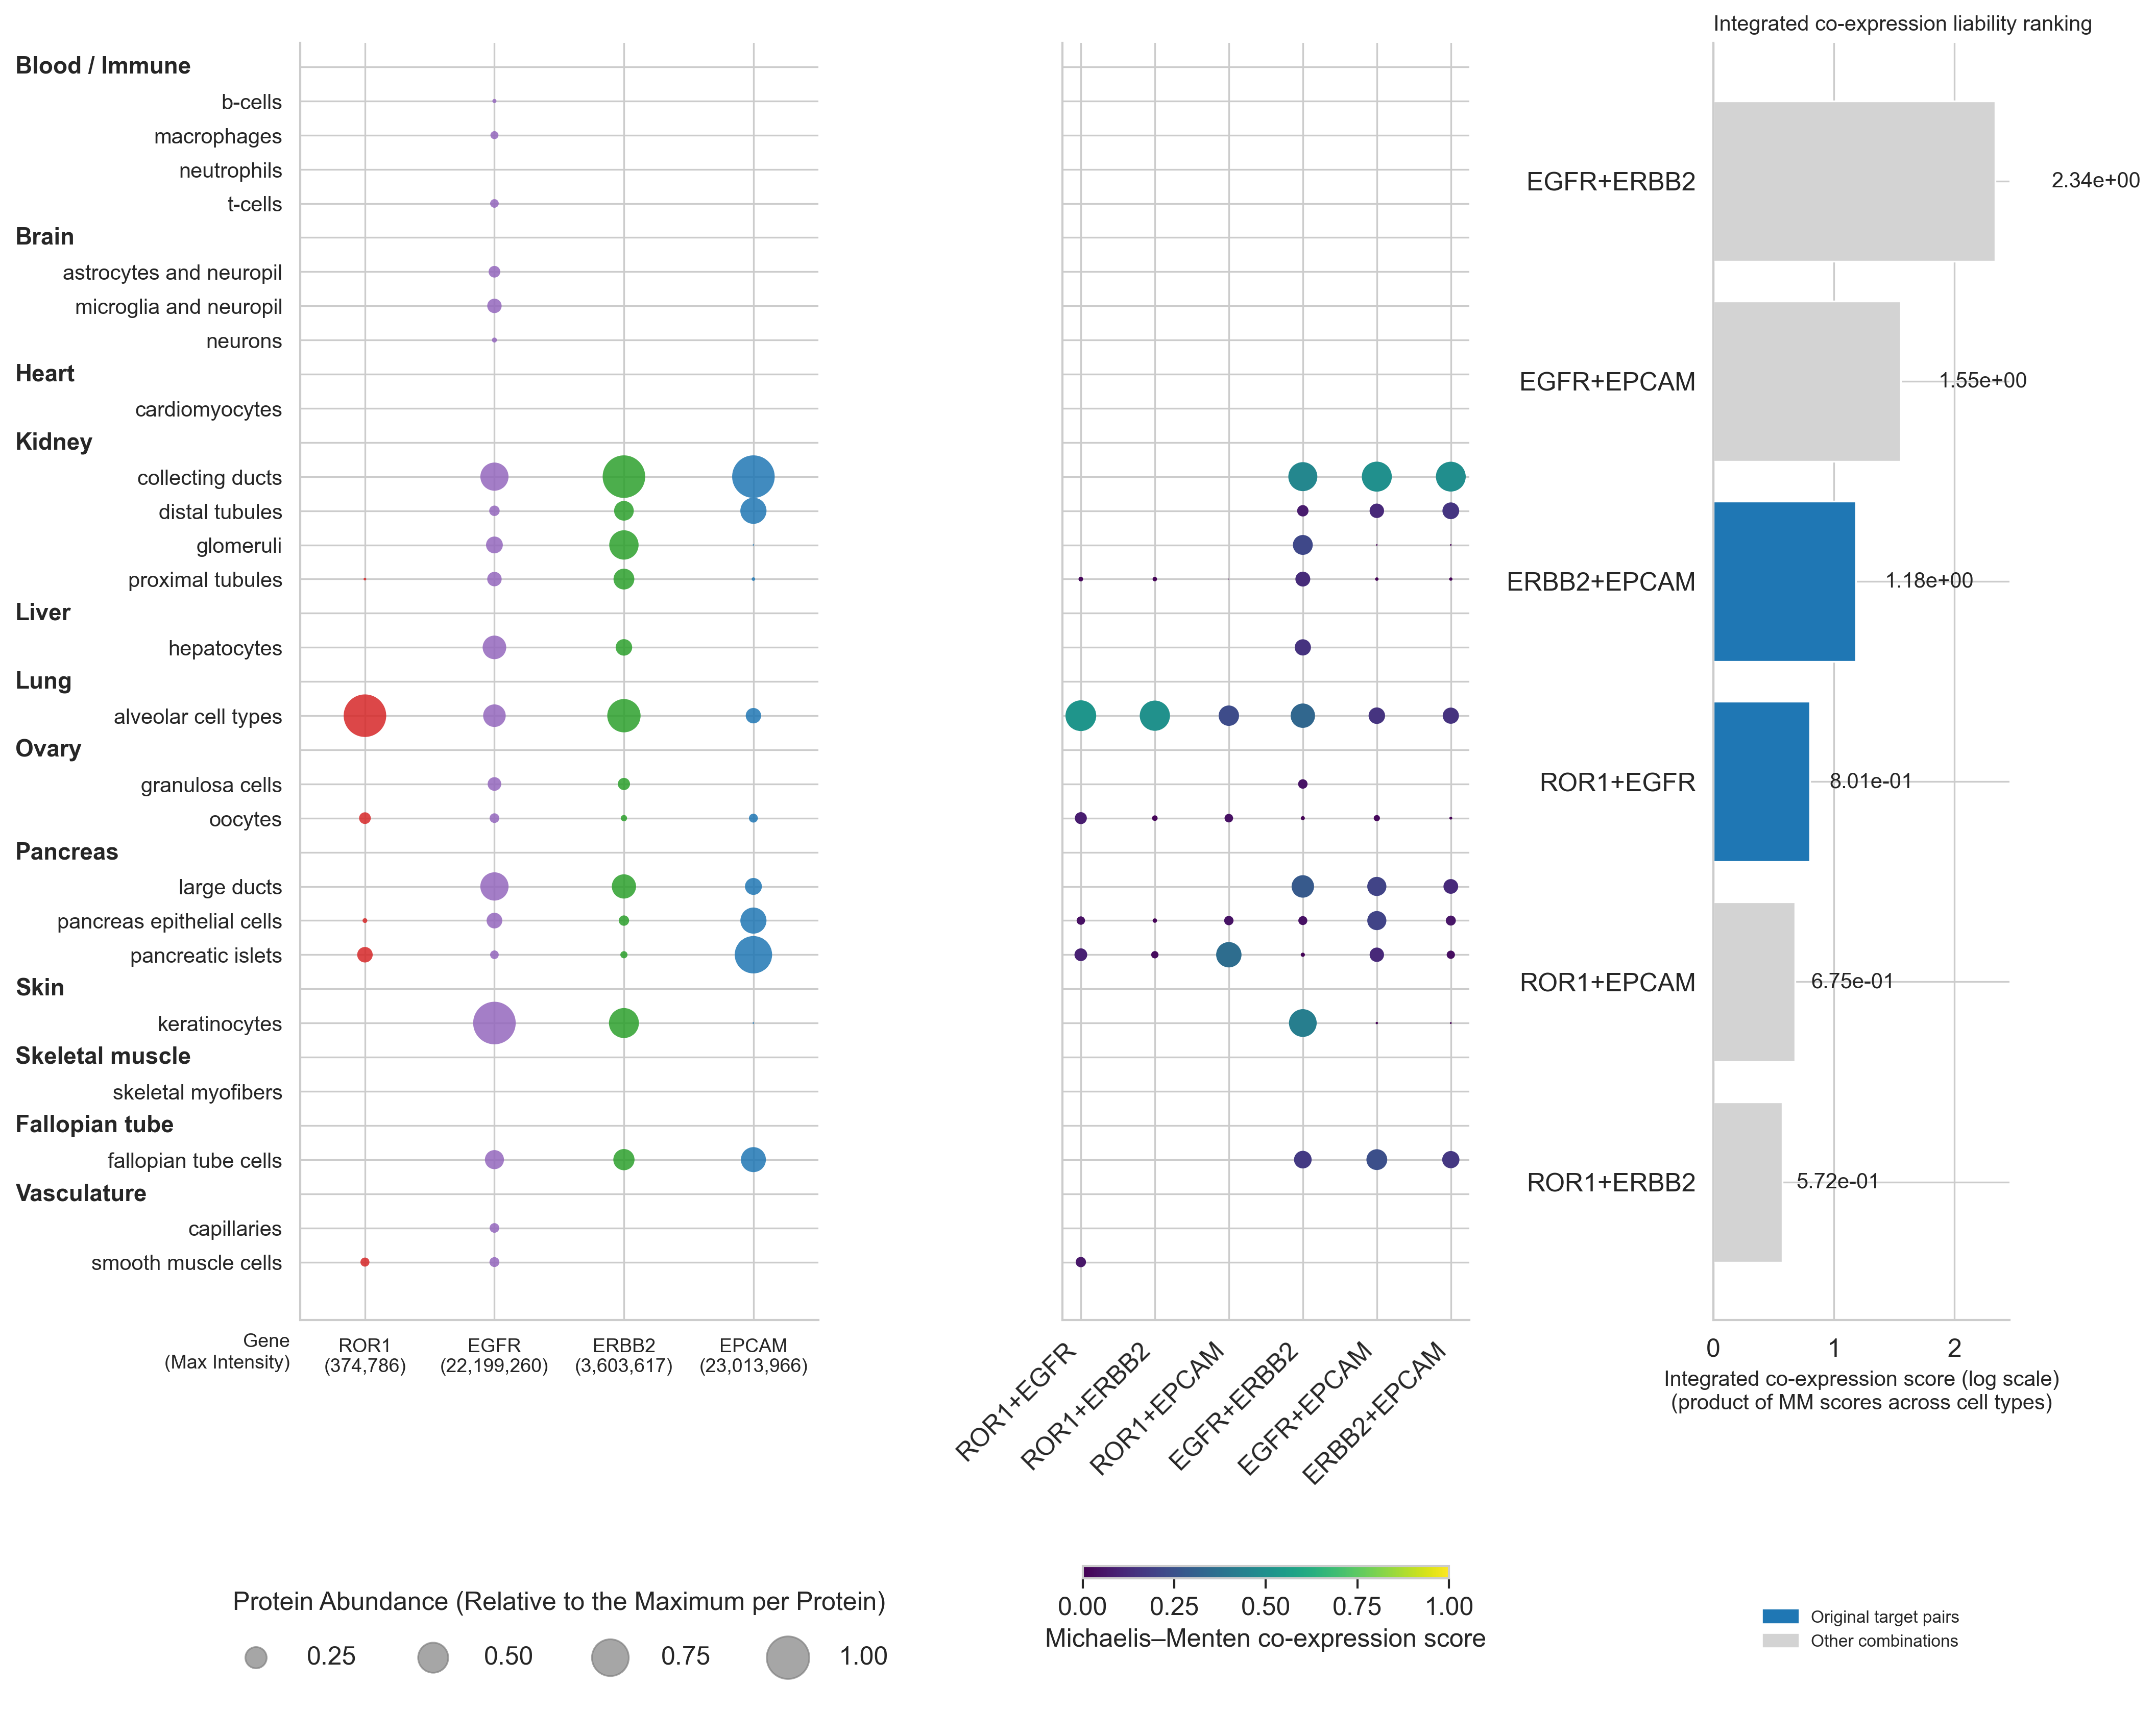

In [19]:
# -------------------------------------------------------------------------
# Figure
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(18, 14))

gs = fig.add_gridspec(
    2, 3,
    height_ratios=[20, 2],
    width_ratios=[1.4, 1.1, 0.8],
    hspace=0.35,
    wspace=0.6,
)

# Main panels
axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])
axC = fig.add_subplot(gs[0, 2])

# Legend panels
legA = fig.add_subplot(gs[1, 0])
legB = fig.add_subplot(gs[1, 1])
legC = fig.add_subplot(gs[1, 2])

# -------------------------------------------------------------------------
# Panel A
# -------------------------------------------------------------------------

plot_abundance_panel(
    axA,
    abundance_wide,
    abundance_norm,
    GENE_ORDER,
    GENE_COLORS,
    plot_rows,
)

# -------------------------------------------------------------------------
# Panel B
# -------------------------------------------------------------------------

sc = plot_coexpression_panel(
    axB,
    coexpression,
    plot_rows,
)

# -------------------------------------------------------------------------
# Panel C
# -------------------------------------------------------------------------

plot_ctli_panel(
    axC,
    ctli,
    TARGET_PAIRS,
)

# -------------------------------------------------------------------------
# Legend A (bubble sizes)
# -------------------------------------------------------------------------
legA.axis("off")

handles = [
    plt.scatter([], [], s=f * SIZE_SCALE,
                color="grey", alpha=0.7)
    for f in [0.25, 0.50, 0.75, 1.00]
]

legA.legend(
    handles,
    ["0.25", "0.50", "0.75", "1.00"],
    title="Protein Abundance (Relative to the Maximum per Protein)",
    ncol=4,
    loc="center",
    frameon=False,
    fontsize=12,
    title_fontsize=12,
    handletextpad=1.0,
    columnspacing=2.0,
    borderpad=1.0,
    labelspacing=1.2,
)

# -------------------------------------------------------------------------
# Legend B (colorbar)
# -------------------------------------------------------------------------
legB.axis("off")

cbar = fig.colorbar(
    sc,
    ax=legB,
    orientation="horizontal",
    fraction=1.0,
    pad=0.4,
    aspect=30,
    shrink=0.9
)

cbar.set_label(
    "Michaelis–Menten co-expression score",
    fontsize=12,
)

# -------------------------------------------------------------------------
# Legend C
# -------------------------------------------------------------------------
legC.axis("off")

highlight_patch = mpatches.Patch(
    color="#1f77b4",
    label="Original target pairs",
)

other_patch = mpatches.Patch(
    color="lightgrey",
    label="Other combinations",
)

legC.legend(
    handles=[highlight_patch, other_patch],
    loc="center",
    frameon=False,
    fontsize=8,
)

plt.subplots_adjust(left=0.28)
#plt.savefig("HPA.png", dpi=300, bbox_inches="tight")
plt.savefig(f"HPA_{K_QUANTILE}.png", dpi=400)
plt.show()